<a href="https://colab.research.google.com/github/harveytheato/Harveytheato-DataScience-GenAI-Submissions/blob/main/Seminar_week_3_Titanic_EDA_COMPLETE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the built-in titanic dataset from seaborn to avoid FileNotFoundError
df = sns.load_dataset("titanic")


In [ ]:
display(df.shape)
display(df.head())
df.info()
display(df.describe())

(891, 15)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.isna().sum()
(df.isna().mean() * 100).round(1)

,0
survived,0.0
pclass,0.0
sex,0.0
age,19.9
sibsp,0.0
parch,0.0
fare,0.0
embarked,0.2
class,0.0
who,0.0


In [ ]:
print(df.isna().sum())
print((df.isna().mean() * 100).round(1))


survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
survived        0.0
pclass          0.0
sex             0.0
age            19.9
sibsp           0.0
parch           0.0
fare            0.0
embarked        0.2
class           0.0
who             0.0
adult_male      0.0
deck           77.2
embark_town     0.2
alive           0.0
alone           0.0
dtype: float64


In [ ]:
df["age"] = df["age"].fillna(df["age"].median())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["HasCabin"] = df["deck"].notna().astype(int)


In [ ]:
print(df.isna().sum())
print(df.columns.tolist())

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
HasCabin         0
dtype: int64
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone', 'HasCabin']


In [ ]:
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])

In [ ]:
print(df.duplicated().sum())
display(df[["age", "fare"]].describe())

110


,age,fare
count,891.000000,891.000000
mean,29.361582,32.204208
std,13.019697,49.693429
min,0.420000,0.000000
25%,22.000000,7.910400
50%,28.000000,14.454200
75%,35.000000,31.000000
max,80.000000,512.329200


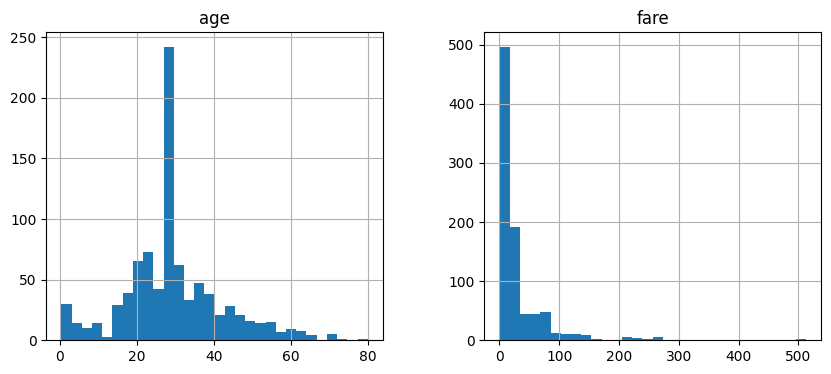

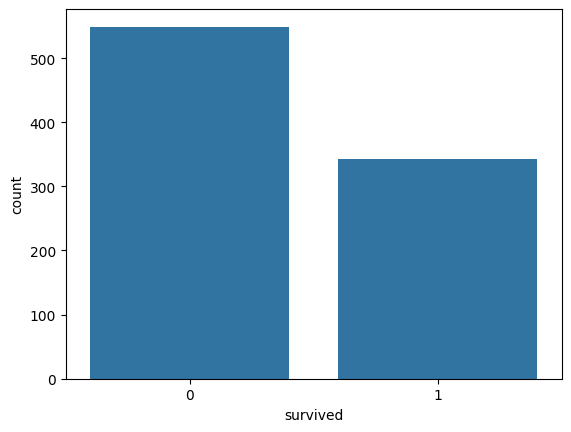

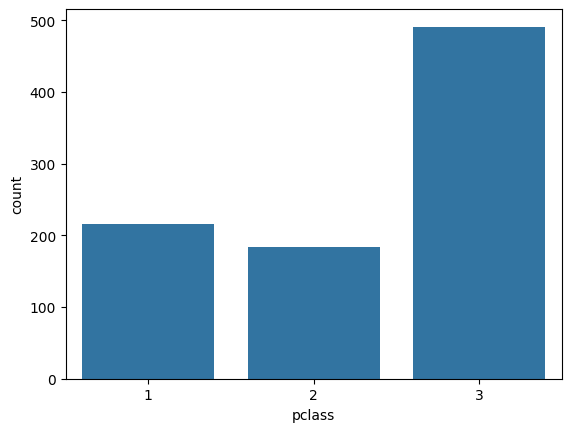

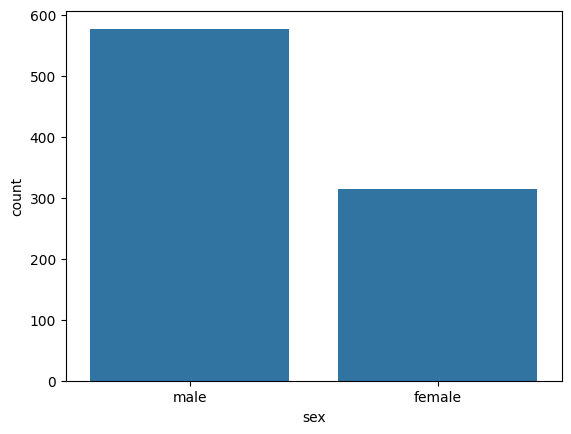

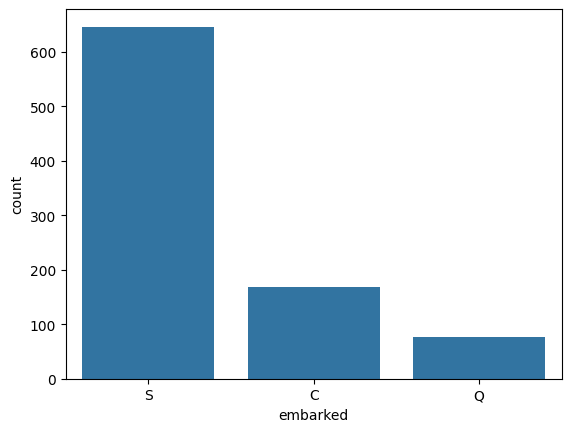

In [ ]:
df[["age", "fare"]].hist(bins=30, figsize=(10, 4))
plt.show()

for col in ["survived", "pclass", "sex", "embarked"]:
    sns.countplot(data=df, x=col)
    plt.show()

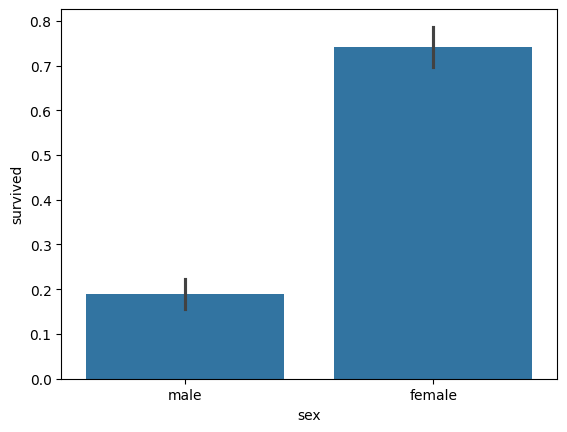

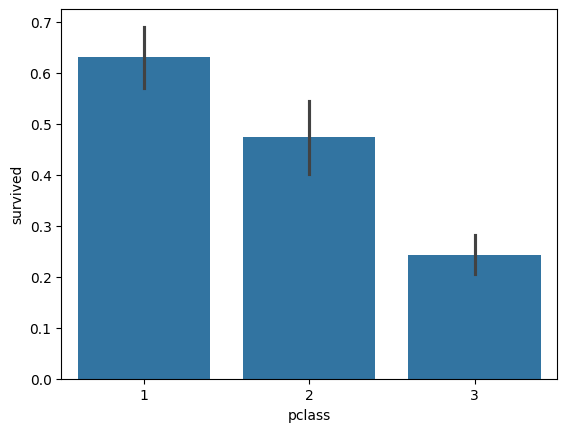

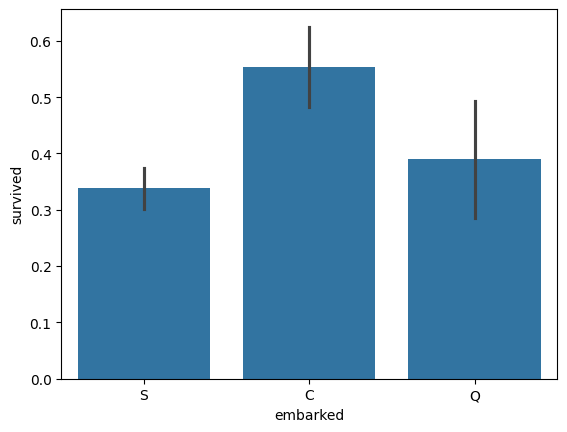

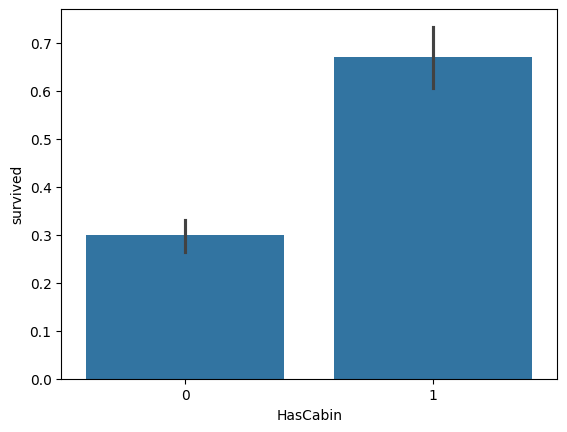

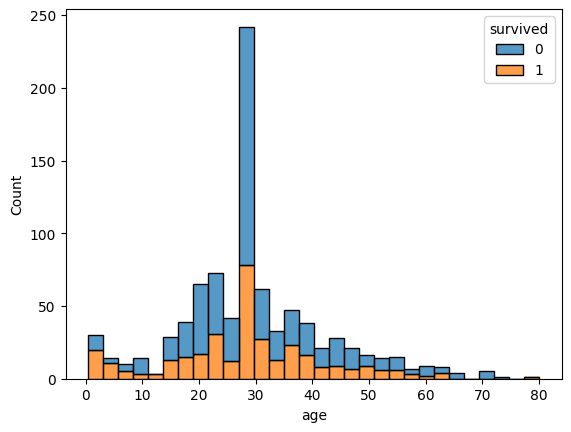

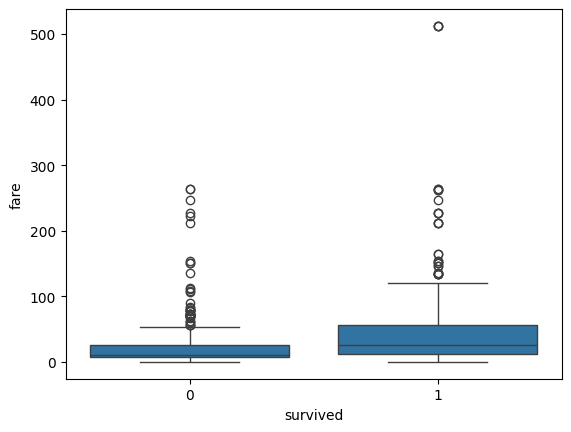

In [ ]:
sns.barplot(data=df, x="sex", y="survived")
plt.show()

sns.barplot(data=df, x="pclass", y="survived")
plt.show()

sns.barplot(data=df, x="embarked", y="survived")
plt.show()

sns.barplot(data=df, x="HasCabin", y="survived")
plt.show()

sns.histplot(data=df, x="age", hue="survived", bins=30, multiple="stack")
plt.show()

sns.boxplot(data=df, x="survived", y="fare")
plt.show()

Sex: far more females survived - probably due to women and children first
Class: the higher the class the more people survived, look slike a very linear relationship
Embarked: most people from C survived despite not many emarbking from there.
Cabin: having cabin way more people survived
Fare: higher fare average survived more on average.

In [ ]:
df.groupby("sex")["survived"].mean().round(3)
df.groupby("pclass")["survived"].mean().round(3)

,survived
pclass,
1,0.630
2,0.473
3,0.242


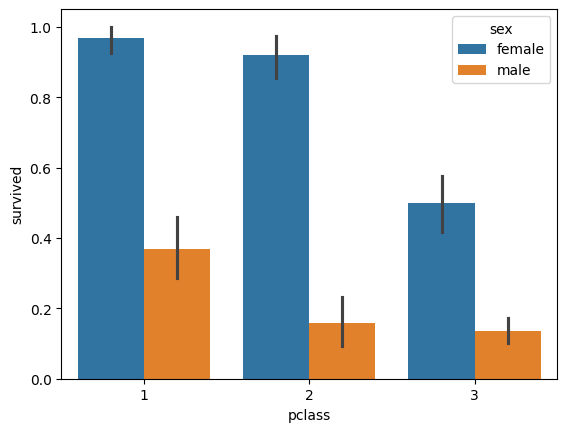

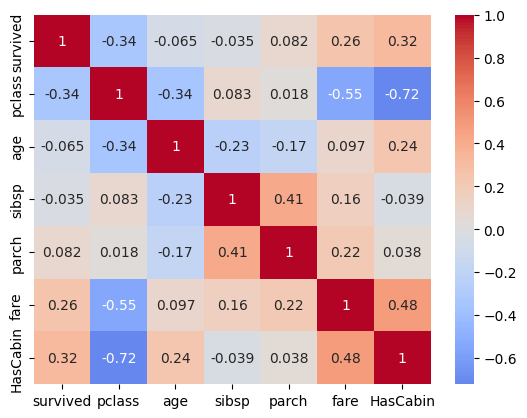

In [ ]:
sns.barplot(data=df, x="pclass", y="survived", hue="sex")
plt.show()

corr = df[["survived", "pclass", "age", "sibsp", "parch", "fare", "HasCabin"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.show()


> Add blockquote



In [ ]:
print(df["survived"].value_counts(normalize=True).round(3))
print(df["sex"].value_counts(normalize=True).round(3))
print(df["pclass"].value_counts(normalize=True).round(3))
print(df["embarked"].value_counts(normalize=True).round(3))
print(df["fare"].agg(["mean", "median", "max"]).round(1))
print(df.groupby("sex")["survived"].mean().round(3))
print(df.groupby("pclass")["survived"].mean().round(3))
print(df.groupby("embarked")["survived"].mean().round(3))
print(df.groupby("HasCabin")["survived"].mean().round(3))
print(df.groupby("survived")["fare"].median().round(1))
print(df.groupby(["pclass", "sex"])["survived"].mean().round(3))
print(pd.crosstab(df["embarked"], df["pclass"], normalize="index").round(2))

print("Hello World!")

survived
0    0.616
1    0.384
Name: proportion, dtype: float64
sex
male      0.648
female    0.352
Name: proportion, dtype: float64
pclass
3    0.551
1    0.242
2    0.207
Name: proportion, dtype: float64
embarked
S    0.725
C    0.189
Q    0.086
Name: proportion, dtype: float64
mean       32.2
median     14.5
max       512.3
Name: fare, dtype: float64
sex
female    0.742
male      0.189
Name: survived, dtype: float64
pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64
embarked
C    0.554
Q    0.390
S    0.339
Name: survived, dtype: float64
HasCabin
0    0.299
1    0.670
Name: survived, dtype: float64
survived
0    10.5
1    26.0
Name: fare, dtype: float64
pclass  sex   
1       female    0.968
        male      0.369
2       female    0.921
        male      0.157
3       female    0.500
        male      0.135
Name: survived, dtype: float64
pclass       1     2     3
embarked                  
C         0.51  0.10  0.39
Q         0.03  0.04  0.94
S         0.20  0

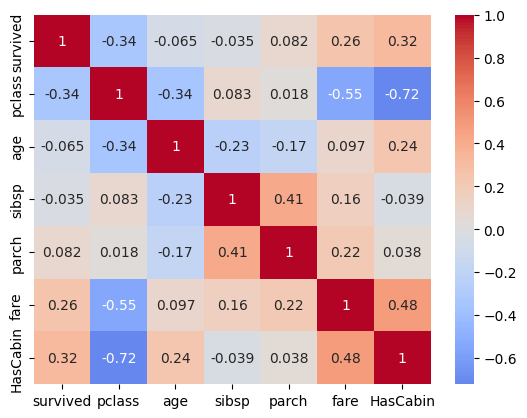

In [ ]:
corr = df[["survived", "pclass", "age", "sibsp", "parch", "fare", "HasCabin"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.show()

**Overview.** Of the 891 passengers, 38.4% survived and 61.6% died. The analysis compared survival across passenger groups and checked how the variables relate to one another.

**1. Sex was the strongest factor.** 74.2% of women survived compared with 18.9% of men, even though men made up 64.8% of passengers. This fits the "women and children first" evacuation policy, although the data alone cannot confirm the reason.

**2. Survival fell with ticket class.** Survival was 63.0% in first class, 47.3% in second and 24.2% in third. The drop was larger between second and third class (23 points) than between first and second (16 points). Third class was also the largest group (55.1% of passengers).

**3. Sex and class acted together.** Women in first and second class survived at 96.8% and 92.1%, but third-class women survived at only 50.0%. Men did poorly in every class (36.9% first, 15.7% second, 13.5% third). Being female helped in every class, but the benefit was much smaller in third class. Third-class women (50.0%) still outsurvived first-class men (36.9%), so sex mattered more than class at the extremes.

**4. Port, cabin and fare mostly reflect class.**
- Passengers who boarded at Cherbourg survived at 55.4%, against 39.0% at Queenstown and 33.9% at Southampton. About 51% of Cherbourg passengers were first class compared with 20% at Southampton, which explains much of the gap. Class does not explain everything, since Queenstown was 94% third class yet outperformed Southampton, and the data cannot say why.
- Passengers with a recorded cabin survived at 67.0% versus 29.9% without one. However, the correlation between having a cabin record and class was -0.72, so this is largely the class effect again.
- Survivors paid a higher median fare (26.0) than non-survivors (10.5). Fare was strongly tied to class (correlation -0.55). Fares were heavily right-skewed (median 14.5, mean 32.2, maximum 512.3).

**5. Age, siblings and parents showed little straight-line relationship with survival.** Their correlations with survival were close to zero (-0.065, -0.035 and 0.082). This does not mean age was irrelevant, since a correlation only detects straight-line patterns, and the age distribution should be examined directly.

## Limitations
- **Missing data.** Age was missing for a fifth of passengers and was filled with the median, which makes the age distribution look narrower than it is and creates an artificial spike near the median. Deck was missing for 688 of 891 passengers (77.2%), so cabin results rest on a small, non-random group whose records may have been better preserved for survivors.
- **Association, not cause.** These are patterns in the data. Class, sex, port and cabin overlap with one another, so no single factor's effect can be isolated from this analysis alone.
- **Heatmap scope.** The correlation grid only covers numeric variables, so it excludes sex, the strongest predictor.
- **Redundant columns.** Several columns duplicated each other (for example, class and pclass, alive and survived), so only one of each pair was used.
- **Sample.** The data covers 891 passengers, which is a subset of everyone aboard, so results may not describe the whole ship.